# 04 Sentence embeddings + logistic regression

**Idea:** TF-IDF only knows which words appear. Two complaints that say the same thing in different words ("they took my car" vs "vehicle was repossessed") share few words, so TF-IDF sees them as different. A **sentence-embedding model** turns each text into a vector (here 384 numbers) so that texts with similar *meaning* end up close together. It learned this from millions of sentence pairs before we ever see it; we use it as-is (no fine-tuning).

**Model:** `sentence-transformers/all-MiniLM-L6-v2`: small (about 90 MB, 6 layers), runs on a CPU. It reads at most **256 tokens** (about 190 words). In our data about 27% of complaints are longer and get cut off at the end (measured on a 2,000-complaint sample).

**Plan:** encode every complaint once (slow, about 30+ minutes on this PC, so we save the result), then fit the same balanced logistic regression as notebook 03, on train, and score on **valid**. Test stays untouched.

## Settings

`SAMPLE = None` uses all complaints. A number (for example 3000) keeps only that many per split: useful for a quick test of the code.

In [1]:
SAMPLE = None
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

In [2]:
from pathlib import Path
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix

ROOT = Path.cwd()
while not (ROOT / "README.md").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed" / "complaints_clean.csv.gz"
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
tag = "" if SAMPLE is None else f"_sample{SAMPLE}"
EMB_FILE = ROOT / "data" / "processed" / f"embeddings_minilm{tag}.npy"
IDS_FILE = ROOT / "data" / "processed" / f"embeddings_minilm{tag}_ids.npy"

df = pd.read_csv(DATA, dtype=str, keep_default_na=False)
if SAMPLE is not None:
    df = df.groupby("split", group_keys=False).sample(SAMPLE, random_state=0)
df = df.reset_index(drop=True)
print(df["split"].value_counts())

split
train    77504
test     42445
valid    18093
Name: count, dtype: int64


## Encode (or load the saved vectors)

- `normalize_embeddings=True` scales every vector to length 1, so only its direction (the "meaning") matters, not its size.
- `batch_size=64`: encode 64 complaints at a time. Bigger is a little faster but uses more memory.
- We save the vectors **and** the matching Complaint IDs. When we load them later, we check the IDs are in the same order as `df`, so vector `i` really belongs to complaint `i`.

In [3]:
if EMB_FILE.exists():
    emb = np.load(EMB_FILE)
    ids = np.load(IDS_FILE, allow_pickle=True)
    assert (ids == df["Complaint ID"].to_numpy()).all(), "saved vectors don't match df order: delete the .npy files and re-run"
    print("loaded saved vectors:", emb.shape)
else:
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer(MODEL_NAME, device="cpu")
    t0 = time.time()
    emb = encoder.encode(df["text"].tolist(), batch_size=64,
                         normalize_embeddings=True, show_progress_bar=True)
    print(f"encoded {len(df):,} complaints in {(time.time() - t0) / 60:.1f} min")
    np.save(EMB_FILE, emb)
    np.save(IDS_FILE, df["Complaint ID"].to_numpy(dtype=object), allow_pickle=True)

print(emb.shape, emb.dtype)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/2157 [00:00<?, ?it/s]

encoded 138,042 complaints in 49.3 min
(138042, 384) float32


In [4]:
# Sanity check: each vector should have length 1 (because of normalize_embeddings=True)
print(np.linalg.norm(emb[:5], axis=1).round(4))

[1. 1. 1. 1. 1.]


## Does "close in meaning" work? A quick look

For one complaint, find the 3 complaints whose vectors are closest. With length-1 vectors, the dot product is the **cosine similarity**: 1 = same direction, 0 = unrelated. If the neighbours are about the same kind of problem, the embedding is doing its job.

In [5]:
i = 0
sims = emb @ emb[i]                  # cosine similarity of complaint i with every complaint
nearest = np.argsort(-sims)[1:4]     # sort high to low, skip position 0 (that's complaint i itself)

print("QUERY |", df.at[i, "Product"], "\n", df.at[i, "text"][:250], "\n")
for j in nearest:
    print(f"sim {sims[j]:.3f} |", df.at[j, "Product"], "\n", df.at[j, "text"][:250], "\n")

QUERY | Credit reporting or other personal consumer reports 
 I am listing accounts below that have been reported inaccurately on my credit report. In compliance with the Fair Credit Reporting Act and as a gesture of respect to the Federal Trade Commission Committee on accuracy and completeness of credit inform 

sim 0.999 | Credit reporting or other personal consumer reports 
 I am listing accounts below that have been reported inaccurately on my credit report. In compliance with the Fair Credit Reporting Act and as a gesture of respect to the Federal Trade Commission Committee on accuracy and completeness of credit inform 

sim 0.998 | Credit reporting or other personal consumer reports 
 I am listing accounts below that have been reported inaccurately on my credit report. In compliance with the Fair Credit Reporting Act and as a gesture of respect to the Federal Trade Commission Committee on accuracy and completeness of credit nforma 

sim 0.998 | Credit reporting or other personal 

## Split the vectors the same way as the data

A boolean mask picks the rows of `emb` that belong to each split.

In [6]:
is_train = (df["split"] == "train").to_numpy()
is_valid = (df["split"] == "valid").to_numpy()

X_train, y_train = emb[is_train], df.loc[is_train, "Product"]
X_valid, y_valid = emb[is_valid], df.loc[is_valid, "Product"]
print(X_train.shape, X_valid.shape)

(77504, 384) (18093, 384)


## Logistic regression on the vectors

Same model as notebook 03, with `class_weight="balanced"`. Now there are only 384 input columns (TF-IDF had about 150,000), so fitting is fast.

`C` controls regularisation: smaller `C` = simpler model (weights pushed towards 0). With few, dense columns the default `C=1` can be too simple, so we try a few values and compare on **valid**. Picking `C` on validation is fine; picking it on test would not be.

In [7]:
rows = []
fitted = {}
for C in [0.3, 1, 3, 10]:
    t0 = time.time()
    clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced")
    clf.fit(X_train, y_train)
    pred = clf.predict(X_valid)
    rows.append({"C": C,
                 "macro_f1": f1_score(y_valid, pred, average="macro", zero_division=0),
                 "weighted_f1": f1_score(y_valid, pred, average="weighted", zero_division=0),
                 "accuracy": (pred == y_valid).mean(),
                 "fit_s": round(time.time() - t0, 1)})
    fitted[C] = clf

c_table = pd.DataFrame(rows).set_index("C").round(3)
c_table

,macro_f1,weighted_f1,accuracy,fit_s
C,,,,
0.3,0.597,0.798,0.772,4.6
1.0,0.598,0.798,0.771,5.2
3.0,0.595,0.797,0.769,8.5
10.0,0.585,0.792,0.764,11.0


In [8]:
best_C = c_table["macro_f1"].idxmax()
emb_clf = fitted[best_C]
pred_emb = emb_clf.predict(X_valid)
print("best C on valid:", best_C)

best C on valid: 1.0


## Compare with TF-IDF (notebook 03) on the same validation rows

We load the saved TF-IDF model and predict the same validation complaints, so both models are scored on exactly the same rows.

In [9]:
tfidf = joblib.load(MODELS / "tfidf_logreg_balanced.joblib")
pred_tfidf = tfidf.predict(df.loc[is_valid, "text"])

def summary(name, pred):
    return {"model": name,
            "macro_f1": f1_score(y_valid, pred, average="macro", zero_division=0),
            "weighted_f1": f1_score(y_valid, pred, average="weighted", zero_division=0),
            "accuracy": (pred == y_valid).mean()}

comparison = pd.DataFrame([
    summary("tfidf + logreg (balanced)", pred_tfidf),
    summary(f"minilm + logreg (balanced, C={best_C})", pred_emb),
]).set_index("model").round(3)
comparison

,macro_f1,weighted_f1,accuracy
model,,,
tfidf + logreg (balanced),0.673,0.836,0.826
"minilm + logreg (balanced, C=1.0)",0.598,0.798,0.771


In [10]:
SHORT = {
    "Credit reporting or other personal consumer reports": "Credit reporting",
    "Money transfer, virtual currency, or money service": "Money transfer",
    "Checking or savings account": "Checking/savings",
    "Debt collection": "Debt collection",
    "Credit card": "Credit card",
    "Mortgage": "Mortgage",
    "Student loan": "Student loan",
    "Vehicle loan or lease": "Vehicle loan",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/personal loan",
    "Other": "Other",
}
ORDER = y_train.value_counts().index.tolist()

def f1_per_class(pred):
    rep = classification_report(y_valid, pred, labels=ORDER, output_dict=True, zero_division=0)
    return pd.Series({SHORT[p]: rep[p]["f1-score"] for p in ORDER})

per_class = pd.DataFrame({
    "f1_tfidf": f1_per_class(pred_tfidf),
    "f1_minilm": f1_per_class(pred_emb),
    "support": y_valid.value_counts().reindex(ORDER).to_numpy(),
})
per_class["diff"] = per_class["f1_minilm"] - per_class["f1_tfidf"]
per_class.round(3)

,f1_tfidf,f1_minilm,support,diff
Credit reporting,0.906,0.875,11566,-0.031
Money transfer,0.830,0.812,1488,-0.018
Checking/savings,0.773,0.735,1237,-0.038
Debt collection,0.664,0.616,1920,-0.048
Credit card,0.646,0.579,818,-0.067
Mortgage,0.832,0.739,270,-0.093
Student loan,0.754,0.678,234,-0.076
Vehicle loan,0.538,0.438,238,-0.100
Other,0.342,0.207,177,-0.135
Payday/personal loan,0.444,0.304,145,-0.139


## Do the two models make the same mistakes?

If they are wrong on different complaints, combining them later could help. If they fail on the same ones, those complaints are probably hard for any model (ambiguous or mislabelled).

In [11]:
right_tfidf = pred_tfidf == y_valid.to_numpy()
right_emb = pred_emb == y_valid.to_numpy()
pd.crosstab(pd.Series(right_tfidf, name="tfidf correct"),
            pd.Series(right_emb, name="minilm correct"), normalize="all").round(3)

minilm correct,False,True
tfidf correct,,
False,0.143,0.032
True,0.086,0.740


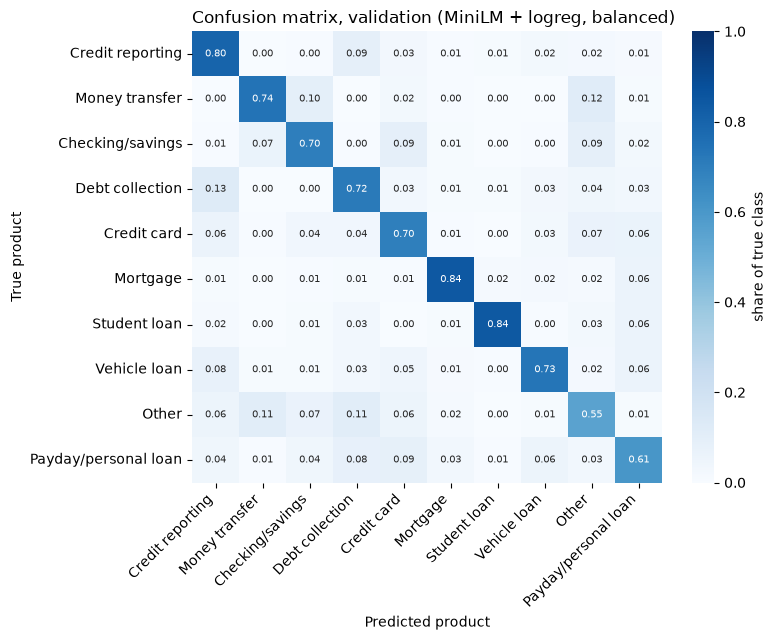

In [12]:
cm = confusion_matrix(y_valid, pred_emb, labels=ORDER, normalize="true")
labels = [SHORT[p] for p in ORDER]

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=labels, yticklabels=labels, cbar_kws={"label": "share of true class"},
            annot_kws={"fontsize": 7}, ax=ax)
ax.set_xlabel("Predicted product")
ax.set_ylabel("True product")
ax.set_title("Confusion matrix, validation (MiniLM + logreg, balanced)", loc="left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
if SAMPLE is None:
    plt.savefig(FIG / "04_confusion_valid.png", dpi=150)
plt.show()

## Save

In [13]:
if SAMPLE is None:
    joblib.dump(emb_clf, MODELS / "minilm_logreg_balanced.joblib")
    c_table.to_csv(ROOT / "reports" / "04_valid_C_search.csv")
    comparison.to_csv(ROOT / "reports" / "04_valid_scores.csv")
    print("saved")
else:
    print("SAMPLE run: nothing saved except the sample vectors")

saved
